# Data undeerstanding

## importing the libraries and dataset

In [4]:
import numpy as np
import pandas as pd
import ydata_profiling as yd  
import seaborn as sns
import matplotlib.pyplot as plt

tafeelah = pd.read_parquet('/mnt/e/Projects/University/3Level_Two/1st Semester/NLP/merged/Ashaar_tafeelah/data/train.parquet')

### Dataset notes

buhr translation: 

| English | بالعربي | العدد في الداتاسيت |
|---|---|---|
| Kamel | الكامل | 128 |
| Mutadarak | المتدارك | 126 |
| Rajaz | الرجز | 120 |
| Ramal | الرمل | 116 |
| Saree | السريع | 96 |
| Mutakareb | المتقارب | 96 |
| Baseet | البسيط | 96 |
| Taweel | الطويل | 72 |
| Khafeef | الخفيف | 51 |
| Munsareh | المنسرح | 40 |
| Madeed | المديد | 20 |
| Wafer | الوافر | 8 |
| Hazaj | الهزج | 6 |
| Mujtath | المجتث | 6 |
| Muqtadheb | المقتضب | 3 |
| Mudhare | المضارع | 2 |

general info:
  - sequence has outliers 
  - no null values
  - there is dublicates in seqeuence column 


dataset use:
  - This dataset tells what the proper تفعيلة is for each weight or each بحر. 
  - It can be used to train a model to predict the تفعيلة of a new sequence.


bottlenecks:
  - There are some sequences that fit more than one bahr, so sometimes we are going to need to hear more than one bait to figure out what the bahr is. 

  - the dataset is not balanced, some bahr have more sequences than others.

  - Everything but the bait itself is written in English. 

  - There is no broken byte or tafeelah in this dataset, And if we needed it To figure out the word that broke the weight, we must add a broken dataset defining the broken word and its solution. 

  - in rows 702 to 752 there is a space in the middle of the word, that will add one more tafeelah if we just used split() function and it should be removed.

  - in rows 803, 807, 811 for example there is فع which is not a valid تفعيلة in general but in mutaqareb it is valid 

  - if the mistake is in the first تفعيلة, then the rest of the تفعيلات will be wrong, so we need to find a way to fix it.

preprocessing hints:
  - We need to arrange the dataset according to the lengths of the tafeelah because it reduces the complexity when searching for the tafeelah. 

  - All the data types are objects. 

  - It must be stratified because all the tafeelah are Grouped 
 

possible feature engineering:
  - We can add a column for the length of the sequence, and we can use it to stratify the dataset, and for fast comparison.
  - adding مجزوء or تامة 
  - foot_start: it is a list of the first letters of each تفعيلة in the sequence, to tell what is the broken tafeelah
  - first_tafeelah, middle_tafeelah, last_tafeelah: to tell what is the broken tafeelah
  - matching every tafeelah with its sequence in a dictionary, to make it easier to find the broken tafeelah
  - meters_set: some sequences can fit more than one meter, so we can add a column for the meters that fit each sequence

after preprocessing:
  - all datasets but ardui and tafeelah are going to be merged into one dataset, and the tafeelah dataset is going to be used to find the broken tafeelah in the sequence and the meter, and ardui dataset will be used to test and validate the model. 



## Data report

In [14]:
tafeelah.head()

,sequence,tafeelah,meter
0,11010110101011010110110,فعولنْ مفاعيلنْ فعولنْ مفاعلنْ,Taweel
1,1101011010101101011010,فعولنْ مفاعيلنْ فعولنْ مفاعي,Taweel
2,110101101010110101101010,فعولنْ مفاعيلنْ فعولنْ مفاعيلنْ,Taweel
3,1101011010101101110110,فعولنْ مفاعيلنْ فعول مفاعلنْ,Taweel
4,110101101010110111010,فعولنْ مفاعيلنْ فعول مفاعي,Taweel


In [15]:
tafeelah.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 986 entries, 0 to 985
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sequence  986 non-null    object
 1   tafeelah  986 non-null    object
 2   meter     986 non-null    object
dtypes: object(3)
memory usage: 23.2+ KB


In [5]:
yd.ProfileReport(tafeelah)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:00<00:00, 36.36it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## columns understanding

### Sequence column:

In [22]:
dups = tafeelah[tafeelah['sequence'].duplicated(keep=False)]  
dups = dups.sort_values('sequence')                           
dups = dups.reset_index().rename(columns={'index': 'orig_index'})
dups

,orig_index,sequence,tafeelah,meter
0,932,101010101011010110,فالنْ فالنْ فاعلنْ فاعلنْ,Mutadarak
1,728,101010101011010110,فالاتنْ مسْتفْع لنْ فاعلا,Khafeef
2,933,10101010101101110,فالنْ فالنْ فاعلنْ فعلنْ,Mutadarak
3,729,10101010101101110,فالاتنْ مسْتفْع لنْ فعلا,Khafeef
4,972,1010101101110,فالنْ فاعلنْ فعلنْ,Mutadarak
...,...,...,...,...
183,659,11110101110101010,متعلنْ مسْتعلنْ مفْعولا,Saree
184,657,11110110110101010,متعلنْ متفْعلنْ مفْعولا,Saree
185,412,11110110110101010,متعلنْ متفْعلنْ مسْتفْعلْ,Rajaz
186,661,1111011110101010,متعلنْ متعلنْ مفْعولا,Saree


### tafeelah column:

In [23]:
# each num of characters in the sequence column
tafeelah['sequence'].str.len().value_counts().sort_index()

sequence
9       2
10      9
11     20
12     40
13     44
14     44
15     55
16    112
17    171
18    172
19    138
20     92
21     53
22     25
23      8
24      1
Name: count, dtype: int64

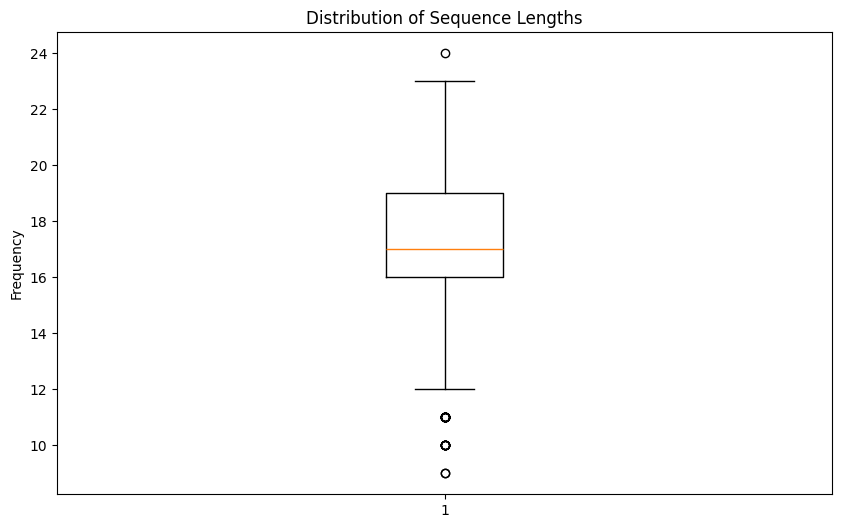

In [32]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.boxplot(x=tafeelah['sequence'].str.len())
plt.title('Distribution of Sequence Lengths')
plt.ylabel('Frequency')
plt.show()


### meter column:

In [21]:
tafeelah['meter'].value_counts()

meter
Kamel        128
Mutadarak    126
Rajaz        120
Ramal        116
Saree         96
Mutakareb     96
Baseet        96
Taweel        72
Khafeef       51
Munsareh      40
Madeed        20
Wafer          8
Hazaj          6
Mujtath        6
Muqtadheb      3
Mudhare        2
Name: count, dtype: int64